# Autoencoder on the T = 48 benign + GridSybil windows with stride-24 overlap (unsupervised)

The same small 1D-conv autoencoder as `task/autoencoder/` (z = 16, 71,741 parameters), now trained on
`src/data/encoder_input/benign_gridsybil/T48_tvt_s24/`: links longer than 48 messages are cut into **overlapping**
windows (stride 24), and the train / val / test split (80 / 10 / 10 by sender vehicle) is fixed on disk. Benign and
GridSybil train windows are both treated as normal: **no labels** in training, model selection or thresholds. The val
split drives early stopping, the LR schedule and the alarm thresholds; the test split is read only in section 5, and
its labels only after every test window has been scored.

Two label-free scores per window: the reconstruction error, and the **Mahalanobis distance** of z to a Gaussian fitted
on the train z. Each is also aggregated per **track** (one link = one receiver hearing one sender pseudonym): max and
mean over the track's windows.

This notebook runs from the repo root, imports the package classes and reads the run folder written by
`npm run aeo:train`. Sections: 1 input, 2 model, 3 training record, 4 reconstruction, 5 test, 6 comparison,
7 analysis.

Setup: repo-root check, package imports, the run folder (the newest `runs/*/summary.json`).

In [1]:
import json
from pathlib import Path

assert Path("task/autoencoder_overlap/config.py").is_file(), "run this notebook from the repo root"

from task.autoencoder_overlap.config import AutoencoderConfig
from task.autoencoder_overlap.data import WindowDataset
from task.autoencoder_overlap.model import ConvAutoencoder, count_params
from task.autoencoder_overlap.scoring import Mahalanobis, TrackScores, quantile_thresholds
from task.autoencoder_overlap.trainer import Trainer

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_fscore_support, roc_auc_score

settings = AutoencoderConfig()
runs = sorted(Path(settings.runs_dir).glob("*/summary.json"), key=lambda p: p.stat().st_mtime)
assert runs, "no finished run: npm run aeo:train"
RUN = runs[-1].parent
META = json.loads((Path(settings.data_dir) / "metadata.json").read_text())
FEATURES = META["features"]
print("run folder:", RUN)
print("data:", settings.data_dir)

run folder: task/autoencoder_overlap/runs/seed0
data: src/data/encoder_input/benign_gridsybil/T48_tvt_s24


## 1. Input

The three splits as written on disk. Sender vehicles never cross splits (checked below). Labels are read here only to
describe the data (class counts); training never reads them.

In [2]:
splits = {name: WindowDataset.load(settings.data_dir, name, workers=settings.workers) for name in ("train", "val", "test")}
train, val, test = splits["train"], splits["val"], splits["test"]
veh = {name: set(d.vehicles) for name, d in splits.items()}
assert not (veh["train"] & veh["val"]) and not (veh["train"] & veh["test"]) and not (veh["val"] & veh["test"])
rows = []
for name, d in splits.items():
    for cls in ("Benign", "GridSybil"):
        s = d.info["label_name"] == cls
        rows.append({"split": name, "class": cls, "windows": int(s.sum()), "tracks": len(set(d.tracks[s])),
                     "sender vehicles": len(set(d.vehicles[s]))})
counts = pd.DataFrame(rows).pivot(index="split", columns="class").loc[["train", "val", "test"]]
counts[("windows", "total")] = counts["windows"].sum(axis=1)
print("no sender vehicle in two splits:", True)
counts

no sender vehicle in two splits: True


windows            tracks           sender vehicles           windows
class  Benign GridSybil  Benign GridSybil          Benign GridSybil   total
split                                                                      
train  117551    213664  101399    181813            3223      1380  331215
val     14172     27268   12218     22810             402       173   41440
test    13964     28689   12053     23904             401       173   42653

Split diagram: windows per split (benign + GridSybil), with the number of sender vehicles behind each split.

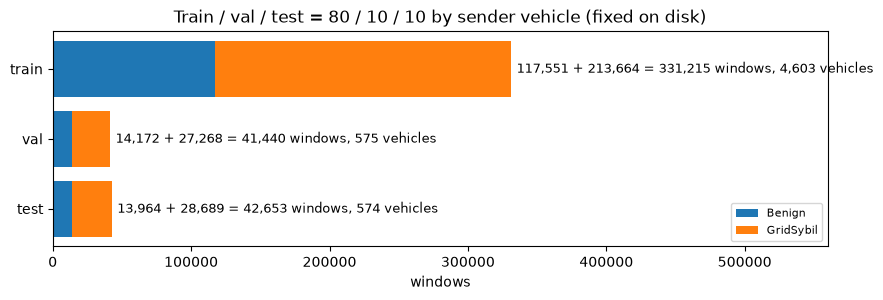

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for y, name in enumerate(("test", "val", "train")):
    b, g = counts.loc[name, ("windows", "Benign")], counts.loc[name, ("windows", "GridSybil")]
    ax.barh(y, b, color="tab:blue", label="Benign" if y == 0 else None)
    ax.barh(y, g, left=b, color="tab:orange", label="GridSybil" if y == 0 else None)
    ax.text(b + g + 4000, y, f"{b:,} + {g:,} = {b + g:,} windows, {len(veh[name]):,} vehicles", va="center", fontsize=9)
ax.set_yticks(range(3), ["test", "val", "train"]); ax.set_xlim(0, 560000); ax.set_xlabel("windows")
ax.legend(loc="lower right", fontsize=8)
ax.set_title("Train / val / test = 80 / 10 / 10 by sender vehicle (fixed on disk)")
plt.show()

**Overlap in one line:** a link of at most 48 messages gives one window; a longer link gives windows starting at
0, 24, 48, ... plus one end-aligned window, so neighbouring windows share up to 24 messages and every message is in at
least one window. Below: windows per track (link) and how many message rows the overlap duplicates.

In [4]:
c = META["counts"]
print(f"links {c['links_kept']:,}; unique messages {c['messages_kept']:,}; message rows in windows "
      f"{c['message_rows_in_windows']:,} (x{c['message_rows_in_windows'] / c['messages_kept']:.3f} from the overlap)")
print(f"links longer than 48: {c['long_links']:,}, cut into {c['windows_of_long_links']:,} windows "
      f"(mean {c['mean_windows_per_long_link']:.2f} per long link)")
tracks = {name: TrackScores(d.tracks) for name, d in splits.items()}
wpt = pd.DataFrame({name: pd.Series(t.n_windows).value_counts().sort_index() for name, t in tracks.items()}).fillna(0)
wpt.index.name = "windows per track"
display(wpt.astype(int).T)
pd.DataFrame({name: {"tracks": len(t), "windows": int(t.n_windows.sum()), "share of tracks with 1 window":
              round(float((t.n_windows == 1).mean()), 3)} for name, t in tracks.items()}).T

links 354,197; unique messages 6,980,356; message rows in windows 8,845,352 (x1.267 from the overlap)
links longer than 48: 31,017, cut into 92,128 windows (mean 2.97 per long link)


windows per track,1,2,3,4,5,6,7,8,9,10,...,23,24,25,26,28,29,30,31,32,35
train,258664,14003,4985,2707,1448,680,234,119,73,57,...,3,2,3,2,1,1,2,2,1,1
val,31888,1753,661,295,203,104,50,21,10,3,...,0,0,0,2,2,0,0,0,0,0
test,32628,1823,732,375,196,93,49,11,9,8,...,0,2,1,0,2,0,0,0,0,0


,tracks,windows,share of tracks with 1 window
train,283212.0,331215.0,0.913
val,35028.0,41440.0,0.910
test,35957.0,42653.0,0.907


Shape: each window is 48 messages (1 Hz) × 13 normalised features; padding rows are zero and the mask marks real rows.
The model gets the 13 features plus the mask as a 14th channel: **14 × 48** per window. Real messages per window and
the padding share:

window x: (48, 13) + mask: (48,) -> model input: (14, 48)


,min,median,mean,max,share = 48,padding share
split,,,,,,
train,1,16.0,21.22,48,0.222,0.558
val,1,16.0,21.43,48,0.233,0.553
test,1,16.0,21.80,48,0.238,0.546


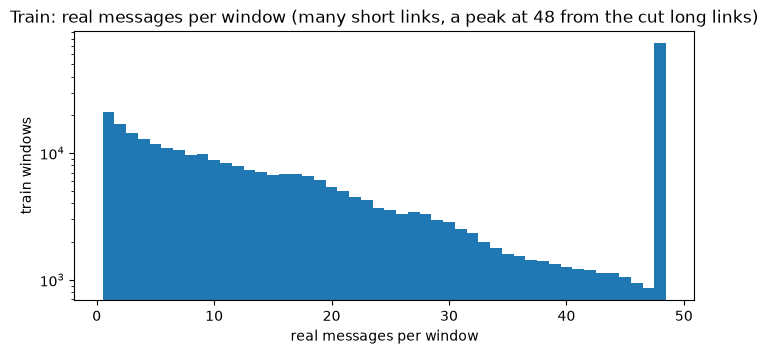

In [5]:
print("window x:", train.x.shape[1:], "+ mask:", train.mask.shape[1:], "-> model input:", (settings.n_features + 1, settings.seq_len))
rows = []
for name, d in splits.items():
    n = d.n_messages
    rows.append({"split": name, "min": n.min(), "median": np.median(n), "mean": round(n.mean(), 2), "max": n.max(),
                 "share = 48": round(float((n == 48).mean()), 3), "padding share": round(1 - d.mask.mean(), 3)})
display(pd.DataFrame(rows).set_index("split"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train.n_messages, bins=np.arange(1, 50) - 0.5, color="tab:blue")
ax.set_xlabel("real messages per window"); ax.set_ylabel("train windows"); ax.set_yscale("log")
ax.set_title("Train: real messages per window (many short links, a peak at 48 from the cut long links)")
plt.show()

Per-feature statistics over the **real** train rows (values are normalised; overlapping rows count once per window).

In [6]:
real = train.x[train.mask]  # (real rows, 13)
pd.DataFrame({"mean": real.mean(0), "std": real.std(0), "min": real.min(0), "max": real.max(0)}, index=FEATURES).round(3)

,mean,std,min,max
claimed_pos_x,-0.022,1.049,-19.788,13.470
claimed_pos_y,-0.003,1.101,-23.966,20.882
rx_pos_x,-0.033,0.975,-1.155,2.326
rx_pos_y,-0.005,0.959,-2.047,2.357
claimed_vel_x,0.011,0.978,-3.539,3.396
claimed_vel_y,0.001,0.972,-3.192,3.036
rx_vel_x,0.010,0.988,-2.527,2.570
rx_vel_y,0.001,0.984,-2.318,2.212
claimed_acl_x,0.002,0.974,-4.678,4.689
claimed_acl_y,0.001,0.975,-3.522,3.541


One train window: the first window of a train track with at least 3 windows, as a heat map of its 13 features (the
dashed line marks the end of the real rows), and where this track's windows start.

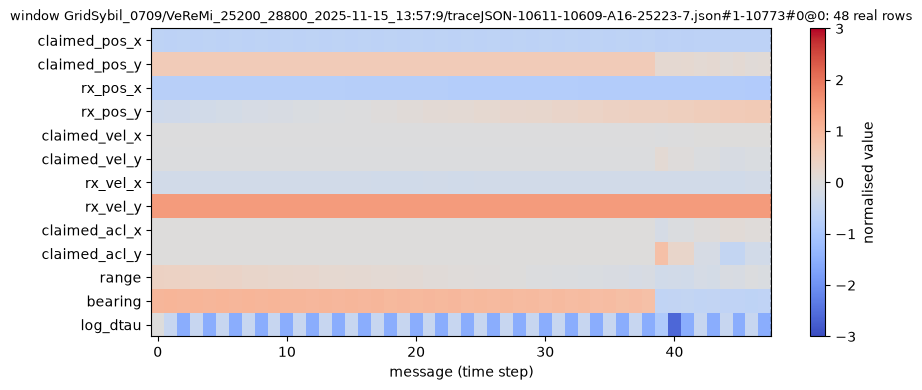

windows of this track (id, start, real rows):
  GridSybil_0709/VeReMi_25200_28800_2025-11-15_13:57:9/traceJSON-10611-10609-A16-25223-7.json#1-10773#0@0 0 48
  GridSybil_0709/VeReMi_25200_28800_2025-11-15_13:57:9/traceJSON-10611-10609-A16-25223-7.json#1-10773#1@24 24 48
  GridSybil_0709/VeReMi_25200_28800_2025-11-15_13:57:9/traceJSON-10611-10609-A16-25223-7.json#1-10773#2@48 48 48
  GridSybil_0709/VeReMi_25200_28800_2025-11-15_13:57:9/traceJSON-10611-10609-A16-25223-7.json#1-10773#3@72 72 48
  GridSybil_0709/VeReMi_25200_28800_2025-11-15_13:57:9/traceJSON-10611-10609-A16-25223-7.json#1-10773#4@96 96 48
  GridSybil_0709/VeReMi_25200_28800_2025-11-15_13:57:9/traceJSON-10611-10609-A16-25223-7.json#1-10773#5@97 97 48


In [7]:
k = int(np.flatnonzero(tracks["train"].n_windows >= 3)[0])
rows_k = np.flatnonzero(tracks["train"].index == k)
rows_k = rows_k[np.argsort(train.info["start"][rows_k].astype(int))]
i = int(rows_k[0]); n = train.n_messages[i]
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(train.x[i].T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
ax.axvline(n - 0.5, color="black", ls="--", lw=1)
ax.set_yticks(range(len(FEATURES)), FEATURES); ax.set_xlabel("message (time step)")
ax.set_title(f"window {train.ids[i]}: {n} real rows", fontsize=9)
fig.colorbar(im, ax=ax, label="normalised value")
plt.show()
print("windows of this track (id, start, real rows):")
for r in rows_k:
    print(" ", train.ids[r], int(train.info["start"][r]), int(train.n_messages[r]))

## 2. Model

Layers with their output shapes for one batch of 2 windows, and the trainable parameter count (same architecture as
`task/autoencoder`).

In [8]:
model = ConvAutoencoder(settings)
x0, m0 = torch.zeros(2, settings.seq_len, settings.n_features), torch.ones(2, settings.seq_len, dtype=torch.bool)
table = []
hooks = [mod.register_forward_hook(lambda mod, inp, out, name=name: table.append(
    (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))))
    for name, mod in model.named_modules() if isinstance(mod, (torch.nn.Conv1d, torch.nn.ConvTranspose1d, torch.nn.Linear))]
model.eval()
with torch.no_grad():
    recon0, z0 = model(x0, m0)
for h in hooks:
    h.remove()
display(pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"]))
print("reconstruction:", tuple(recon0.shape[1:]), " z:", tuple(z0.shape[1:]))
print(f"trainable parameters: {count_params(model):,}")

,layer,type,output (per window),params
0,encoder_conv.0,Conv1d,"(32, 48)",1376
1,encoder_conv.3,Conv1d,"(64, 24)",6208
2,encoder_conv.6,Conv1d,"(64, 12)",12352
3,to_z,Linear,"(16,)",12304
4,from_z,Linear,"(768,)",13056
5,decoder_conv.1,ConvTranspose1d,"(64, 24)",16448
6,decoder_conv.4,ConvTranspose1d,"(32, 48)",8224
7,decoder_conv.7,Conv1d,"(13, 48)",1261


reconstruction: (48, 13)  z: (16,)
trainable parameters: 71,741


## 3. Training record

What `task.autoencoder_overlap.train` wrote: the summary (incl. the val thresholds), the per-epoch history (train vs
validation masked MSE, best epoch, LR drops; then the mean gradient L2 norm and the LR per epoch) and log lines.

{
  "run_id": "seed0",
  "params": 71741,
  "best_epoch": 139,
  "best_val_loss": 0.14267147857223592,
  "epochs_run": 149,
  "stop_reason": "early_stopping",
  "lr_changes": [
    {
      "after_epoch": 39,
      "from": 0.001,
      "to": 0.0005
    },
    {
      "after_epoch": 65,
      "from": 0.0005,
      "to": 0.00025
    },
    {
      "after_epoch": 80,
      "from": 0.00025,
      "to": 0.000125
    },
    {
      "after_epoch": 103,
      "from": 0.000125,
      "to": 6.25e-05
    },
    {
      "after_epoch": 115,
      "from": 6.25e-05,
      "to": 3.125e-05
    },
    {
      "after_epoch": 122,
      "from": 3.125e-05,
      "to": 1.5625e-05
    },
    {
      "after_epoch": 136,
      "from": 1.5625e-05,
      "to": 7.8125e-06
    },
    {
      "after_epoch": 145,
      "from": 7.8125e-06,
      "to": 3.90625e-06
    }
  ],
  "train_seconds": 841.6,
  "train_windows": 331215,
  "val_windows": 41440,
  "train_tracks": 283212,
  "val_tracks": 35028,
  "mahalanobis": {
 

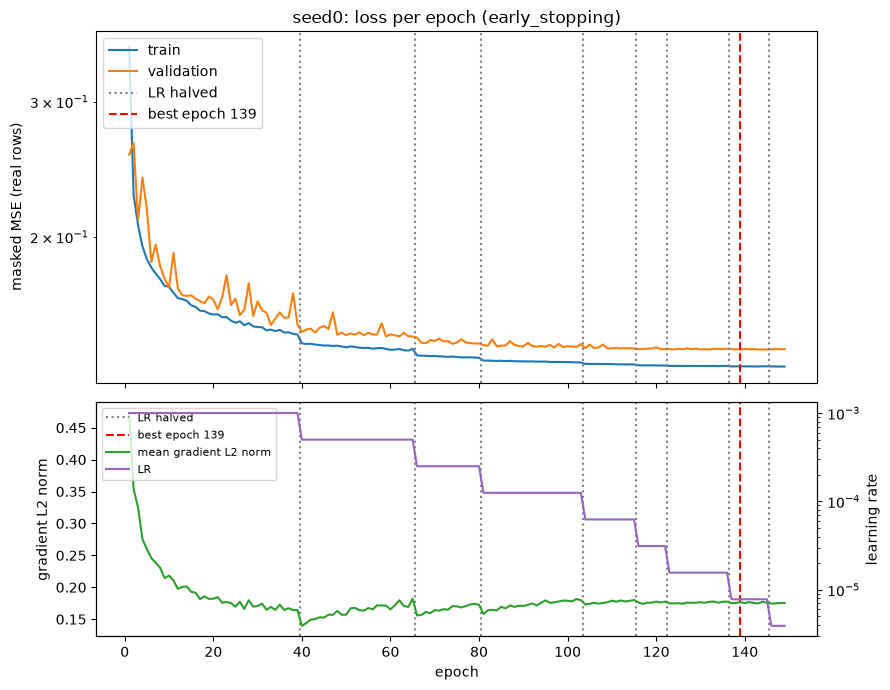

2026-10-28T01:45:28 train 331,215 / val 41,440 windows (7s to load), shape (48, 13) + mask; vehicles 4,603 / 575; tracks 283,212 / 35,028
2026-10-28T01:45:29 padding share train 0.558 / val 0.553, real messages per window median 16, windows per track mean 1.169 / max 35
2026-10-28T01:45:29 ConvAutoencoder: 71,741 trainable parameters, input 14 x 48, z 16
2026-10-28T01:45:29 fit: 331,215 windows, val: 41,440 windows, batch 256, device mps, min_delta 0.0001 (relative), patience 10
2026-10-28T01:45:36 epoch   1  train 0.35300  val 0.25582  lr 1.00e-03  grad_norm 0.4730  6.5s *best
...
2026-10-28T01:49:12 lr reduced 1.00e-03 -> 5.00e-04 (validation loss flat for 6 epochs)
2026-10-28T01:51:39 lr reduced 5.00e-04 -> 2.50e-04 (validation loss flat for 6 epochs)
...
2026-10-28T01:59:31 early stopping: no improvement for 10 epochs; best epoch 139 val 0.14267
2026-10-28T01:59:32 mahalanobis on train z: condition number 38.6, shrinkage 0
2026-10-28T01:59:32 val thresholds: {"window": {"reconstruc

In [9]:
summary = json.loads((RUN / "summary.json").read_text())
print(json.dumps({k: v for k, v in summary.items() if k != "thresholds"}, indent=2))
history = pd.read_json(RUN / "history.jsonl", lines=True)
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=(3, 2))
ax.plot(history.epoch, history.train_loss, label="train")
ax.plot(history.epoch, history.val_loss, label="validation")
for a in (ax, ax2):
    for k, c in enumerate(summary["lr_changes"]):
        a.axvline(c["after_epoch"] + 0.5, color="grey", ls=":", label="LR halved" if k == 0 else None)
    a.axvline(summary["best_epoch"], color="red", ls="--", label=f"best epoch {summary['best_epoch']}")
ax.set_yscale("log"); ax.set_ylabel("masked MSE (real rows)"); ax.legend()
ax.set_title(f"{RUN.name}: loss per epoch ({summary['stop_reason']})")
ax2.plot(history.epoch, history.grad_norm, color="tab:green", label="mean gradient L2 norm")
ax2.set_ylabel("gradient L2 norm"); ax2.set_xlabel("epoch")
lr_ax = ax2.twinx(); lr_ax.plot(history.epoch, history.lr, color="tab:purple", label="LR"); lr_ax.set_yscale("log")
lr_ax.set_ylabel("learning rate")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = lr_ax.get_legend_handles_labels(); ax2.legend(h1 + h2, l1 + l2, fontsize=8)
fig.tight_layout(); plt.show()
log = (RUN / "train.log").read_text().splitlines()
print("\n".join(log[:5] + ["..."] + [l for l in log if "lr reduced" in l][:2] + ["..."] + log[-4:-1]))

## 4. Reconstruction on val

Load `best.pt` and rebuild the val windows. A few long val windows: input vs reconstruction for three features. Then
the mean reconstruction error per feature over val.

val windows 41,440; mean window error 0.1356 (run's best val loss, pooled over rows: 0.1427)


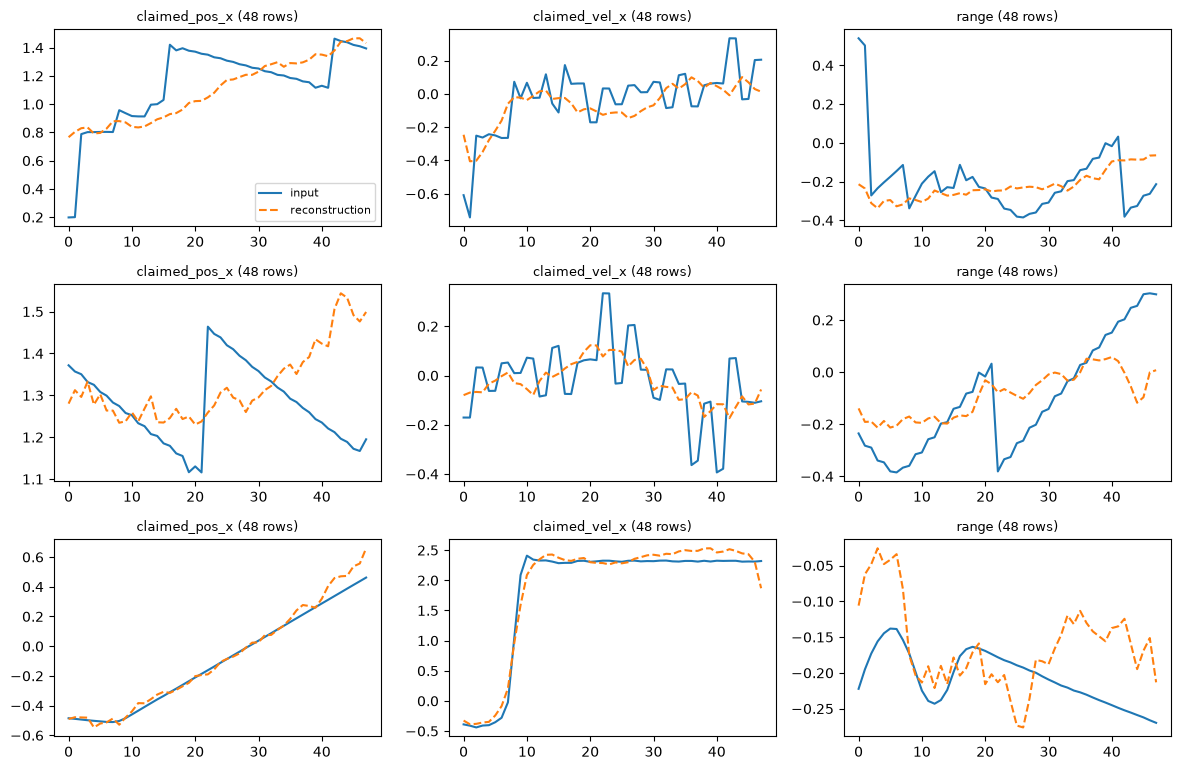

,val MSE
claimed_acl_x,0.4219
claimed_acl_y,0.3751
log_dtau,0.2856
bearing,0.1657
rx_vel_x,0.1211
rx_vel_y,0.1056
claimed_vel_x,0.0749
claimed_vel_y,0.0688
range,0.0458
claimed_pos_x,0.0332


In [10]:
trainer = Trainer.from_checkpoint(RUN / "best.pt")
cfg = trainer.settings
val_out = trainer.score(val.x, val.mask, keep_recon=True)
print(f"val windows {len(val):,}; mean window error {val_out['error'].mean():.4f} "
      f"(run's best val loss, pooled over rows: {summary['best_val_loss']:.4f})")

show = ["claimed_pos_x", "claimed_vel_x", "range"]
picks = np.flatnonzero(val.n_messages >= 30)[:3]
fig, axes = plt.subplots(len(picks), len(show), figsize=(12, 2.6 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    n = val.n_messages[i]
    for c, f in enumerate(show):
        j = FEATURES.index(f)
        axes[r, c].plot(val.x[i, :n, j], label="input")
        axes[r, c].plot(val_out["recon"][i, :n, j], "--", label="reconstruction")
        axes[r, c].set_title(f"{f} ({n} rows)", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

pd.Series(val_out["error_feature"].mean(0), index=FEATURES, name="val MSE").sort_values(ascending=False).round(4).to_frame()

## 5. Test

**Scoring first, labels after.** The Mahalanobis model stored by the run (`mahalanobis.npz`, fitted on train z) is
checked against a refit on train z here. Every val and test window gets its reconstruction error and Mahalanobis
distance; per-track scores are the max and mean over each track's windows. Thresholds = 95th / 99th percentile of the
**val** scores (window level) or of the val track scores (track level); they are recomputed and compared with the run's
summary.

In [11]:
maha = Mahalanobis.from_state(np.load(RUN / "mahalanobis.npz"))
refit = Mahalanobis(cfg.mahalanobis_max_cond, cfg.mahalanobis_shrinkage).fit(trainer.score(train.x, train.mask)["z"])
print(f"mahalanobis: cond {maha.cond:.3g}, shrinkage {maha.shrinkage:g}; refit on train z matches: "
      f"{np.allclose(maha.mean, refit.mean, atol=1e-5) and np.allclose(maha.precision, refit.precision, rtol=1e-3, atol=1e-4)}")

test_out = trainer.score(test.x, test.mask)
window_scores = {
    "val": {"reconstruction": val_out["error"], "mahalanobis": maha.score(val_out["z"])},
    "test": {"reconstruction": test_out["error"], "mahalanobis": maha.score(test_out["z"])},
}
LEVELS = ["window", "track max", "track mean"]
scores = {sp: {} for sp in ("val", "test")}
for sp in ("val", "test"):
    for name, s in window_scores[sp].items():
        scores[sp][(name, "window")] = s
        agg = tracks[sp].aggregate(s)
        scores[sp][(name, "track max")], scores[sp][(name, "track mean")] = agg["max"], agg["mean"]
thresholds = {key: quantile_thresholds(v, cfg.threshold_quantiles) for key, v in scores["val"].items()}
run_thr = summary["thresholds"]
same = all(np.isclose(thresholds[(n, "window")][q], run_thr["window"][n][q]) and
           np.isclose(thresholds[(n, "track max")][q], run_thr["track"][f"{n}_max"][q]) and
           np.isclose(thresholds[(n, "track mean")][q], run_thr["track"][f"{n}_mean"][q])
           for n in ("reconstruction", "mahalanobis") for q in ("p95", "p99"))
print("val thresholds equal the run's summary:", same)
print(f"scored {len(test):,} test windows in {len(tracks['test']):,} tracks")

mahalanobis: cond 38.6, shrinkage 0; refit on train z matches: True
val thresholds equal the run's summary: True
scored 42,653 test windows in 35,957 tracks


Labels are read now (GridSybil = positive). Track label = majority of its windows; mixed tracks are counted.

In [12]:
y_win = (test.info["label"].astype(int) == 16).astype(int)
y_trk, mixed = tracks["test"].track_labels(y_win)
_, mixed_val = tracks["val"].track_labels((val.info["label"].astype(int) == 16).astype(int))
print(f"tracks whose windows disagree on the label: test {mixed}, val {mixed_val}")
print(f"windows: benign {int((y_win == 0).sum()):,}, GridSybil {int(y_win.sum()):,} (share {y_win.mean():.3f})")
print(f"tracks:  benign {int((y_trk == 0).sum()):,}, GridSybil {int(y_trk.sum()):,} (share {y_trk.mean():.3f})")

tracks whose windows disagree on the label: test 0, val 0
windows: benign 13,964, GridSybil 28,689 (share 0.673)
tracks:  benign 12,053, GridSybil 23,904 (share 0.665)


AUROC, PR-AUC (chance = GridSybil share) and precision / recall / F1 / benign FPR at the val-p95 and val-p99
thresholds, per window and per track, for both scores.

In [13]:
def metrics(y, s, theta):
    pred = (s > theta).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"precision": p, "recall": r, "F1": f1, "benign FPR": fp / (fp + tn), "tn": tn, "fp": fp, "fn": fn, "tp": tp}

rows = []
for name in ("reconstruction", "mahalanobis"):
    for level in LEVELS:
        s = scores["test"][(name, level)]
        y = y_win if level == "window" else y_trk
        base = {"score": name, "level": level, "AUROC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                "chance": y.mean()}
        for q in ("p95", "p99"):
            rows.append({**base, "threshold": q, "θ": thresholds[(name, level)][q],
                         **metrics(y, s, thresholds[(name, level)][q])})
res = pd.DataFrame(rows)
display(res.drop(columns=["tn", "fp", "fn", "tp"]).set_index(["score", "level", "threshold"]).round(3))

AUROC  PR-AUC  chance      θ  precision  \
score          level      threshold                                            
reconstruction window     p95        0.484   0.664   0.673  0.401      0.637   
                          p99        0.484   0.664   0.673  0.614      0.691   
               track max  p95        0.482   0.655   0.665  0.409      0.630   
                          p99        0.482   0.655   0.665  0.627      0.691   
               track mean p95        0.481   0.654   0.665  0.396      0.622   
                          p99        0.481   0.654   0.665  0.610      0.649   
mahalanobis    window     p95        0.337   0.595   0.673  5.983      0.573   
                          p99        0.337   0.595   0.673  7.767      0.894   
               track max  p95        0.307   0.565   0.665  5.613      0.499   
                          p99        0.307   0.565   0.665  7.010      0.634   
               track mean p95        0.302   0.559   0.665  5.459      0.461   
                          p99        0.302   0.559   0.665  6.686      0.584   

                                     recall     F1  benign FPR  
score          level      threshold                             
reconstruction window     p95         0.043  0.080       0.050  
                          p99         0.009  0.017       0.008  
               track max  p95         0.044  0.082       0.051  
                          p99         0.009  0.018       0.008  
               track mean p95         0.044  0.082       0.053  
                          p99         0.008  0.016       0.009  
mahalanobis    window     p95         0.044  0.082       0.068  
                          p99         0.009  0.019       0.002  
               track max  p95         0.039  0.072       0.077  
                          p99         0.010  0.019       0.011  
               track mean p95         0.036  0.066       0.083  
                          p99         0.008  0.015       0.011

Confusion matrices at the val-p95 threshold (rows = truth, columns = prediction).

In [14]:
for _, r in res[res.threshold == "p95"].iterrows():
    cm = pd.DataFrame([[r.tn, r.fp], [r.fn, r.tp]], index=["true benign", "true GridSybil"],
                      columns=["pred benign", "pred GridSybil"])
    print(f"{r.score}, {r.level} (θ = {r['θ']:.4f})"); display(cm)

reconstruction, window (θ = 0.4010)


,pred benign,pred GridSybil
true benign,13269,695
true GridSybil,27469,1220


reconstruction, track max (θ = 0.4093)


,pred benign,pred GridSybil
true benign,11440,613
true GridSybil,22859,1045


reconstruction, track mean (θ = 0.3961)


...

,pred benign,pred GridSybil
true benign,13014,950
true GridSybil,27414,1275


mahalanobis, track max (θ = 5.6130)


,pred benign,pred GridSybil
true benign,11119,934
true GridSybil,22975,929


mahalanobis, track mean (θ = 5.4586)


,pred benign,pred GridSybil
true benign,11054,999
true GridSybil,23051,853


Score histograms, benign vs GridSybil, per window and per track (max), with the val-p95 threshold.

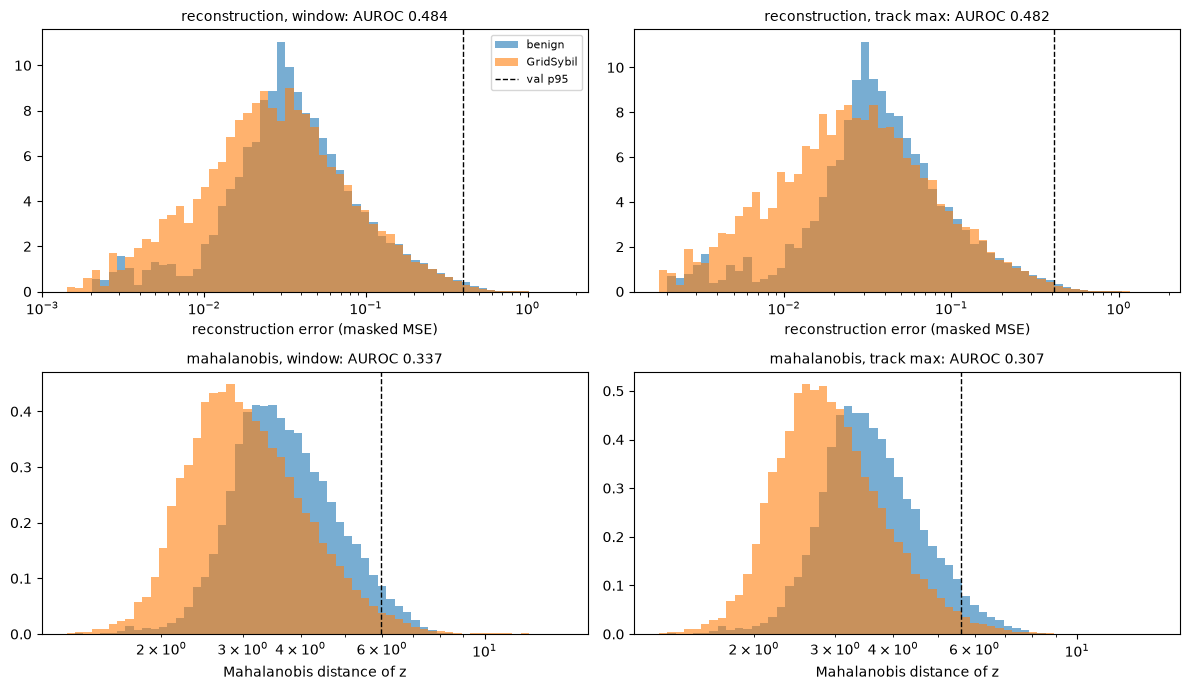

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r, name in enumerate(("reconstruction", "mahalanobis")):
    for c, level in enumerate(("window", "track max")):
        s = scores["test"][(name, level)]
        y = y_win if level == "window" else y_trk
        ax = axes[r, c]
        lo = max(s.min(), 1e-5)
        bins = np.logspace(np.log10(lo), np.log10(s.max()), 60)
        ax.hist(s[y == 0], bins=bins, alpha=0.6, density=True, label="benign")
        ax.hist(s[y == 1], bins=bins, alpha=0.6, density=True, label="GridSybil")
        ax.axvline(thresholds[(name, level)]["p95"], color="black", ls="--", lw=1, label="val p95")
        ax.set_xscale("log"); ax.set_title(f"{name}, {level}: AUROC {roc_auc_score(y, s):.3f}", fontsize=10)
        ax.set_xlabel("reconstruction error (masked MSE)" if name == "reconstruction" else "Mahalanobis distance of z")
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

Mean per-feature reconstruction error by class on the test windows, and the per-feature AUROC.

In [16]:
ef = test_out["error_feature"]
pd.DataFrame({
    "benign": ef[y_win == 0].mean(0),
    "GridSybil": ef[y_win == 1].mean(0),
    "AUROC": [roc_auc_score(y_win, ef[:, j]) for j in range(ef.shape[1])],
}, index=FEATURES).round(4).sort_values("AUROC", ascending=False)

,benign,GridSybil,AUROC
range,0.0183,0.0500,0.6601
claimed_pos_y,0.0120,0.0348,0.6265
log_dtau,0.1745,0.3247,0.6047
claimed_pos_x,0.0150,0.0353,0.5678
bearing,0.1251,0.1712,0.5470
rx_pos_y,0.0166,0.0207,0.5221
rx_pos_x,0.0155,0.0184,0.5024
rx_vel_y,0.1052,0.0960,0.4716
claimed_acl_y,0.4011,0.3898,0.4649
rx_vel_x,0.1233,0.1094,0.4594


2-D PCA of the test latent z, coloured by class (inspection only; z was never trained to separate classes).

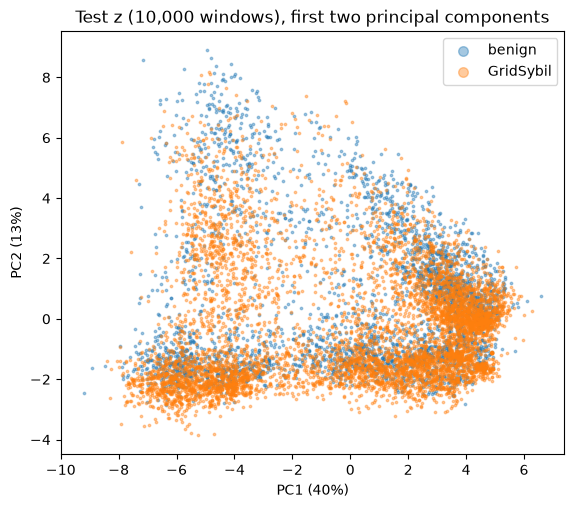

In [17]:
rng = np.random.default_rng(0)
sub = rng.choice(len(y_win), size=min(10000, len(y_win)), replace=False)
pca = PCA(2, random_state=0).fit(test_out["z"])
zz = pca.transform(test_out["z"][sub])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for cls, name in [(0, "benign"), (1, "GridSybil")]:
    s = y_win[sub] == cls
    ax.scatter(zz[s, 0], zz[s, 1], s=3, alpha=0.4, label=name)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=4); ax.set_title("Test z (10,000 windows), first two principal components")
plt.show()

## 6. Comparison (context only)

`task/autoencoder` seed0 (T48 without overlap, 90 / 10 split with 10% of train vehicles as validation) reached
window-level reconstruction AUROC **0.484** on its own test split (README of that folder). The windows are cut
differently and the train / val vehicles differ (the test vehicles are the same set), so this is context, not a
controlled comparison.

In [18]:
cmp = res[(res.threshold == "p95")].set_index(["score", "level"])[["AUROC", "PR-AUC", "chance", "recall", "benign FPR"]]
cmp.loc[("task/autoencoder seed0 (no overlap), reconstruction", "window"), ["AUROC", "PR-AUC", "chance", "recall", "benign FPR"]] = [0.484, 0.661, 0.669, 0.046, 0.049]
cmp.round(3)

AUROC  PR-AUC  \
score                                              level                       
reconstruction                                     window      0.484   0.664   
                                                   track max   0.482   0.655   
                                                   track mean  0.481   0.654   
mahalanobis                                        window      0.337   0.595   
                                                   track max   0.307   0.565   
                                                   track mean  0.302   0.559   
task/autoencoder seed0 (no overlap), reconstruc... window      0.484   0.661   

                                                               chance  recall  \
score                                              level                        
reconstruction                                     window       0.673   0.043   
                                                   track max    0.665   0.044   
                                                   track mean   0.665   0.044   
mahalanobis                                        window       0.673   0.044   
                                                   track max    0.665   0.039   
                                                   track mean   0.665   0.036   
task/autoencoder seed0 (no overlap), reconstruc... window       0.669   0.046   

                                                               benign FPR  
score                                              level                   
reconstruction                                     window           0.050  
                                                   track max        0.051  
                                                   track mean       0.053  
mahalanobis                                        window           0.068  
                                                   track max        0.077  
                                                   track mean       0.083  
task/autoencoder seed0 (no overlap), reconstruc... window           0.049

The numbers the analysis below refers to.

In [19]:
results = {"run": RUN.name, "best_epoch": summary["best_epoch"], "best_val_loss": round(summary["best_val_loss"], 5),
           "epochs_run": summary["epochs_run"], "mixed_label_tracks": mixed}
for _, r in res.iterrows():
    key = f"{r.score}/{r.level}/{r.threshold}"
    results[key] = {k: round(float(r[k]), 3) for k in ("AUROC", "PR-AUC", "precision", "recall", "F1", "benign FPR")}
results

{'run': 'seed0',
 'best_epoch': 139,
 'best_val_loss': 0.14267,
 'epochs_run': 149,
 'mixed_label_tracks': 0,
 'reconstruction/window/p95': {'AUROC': 0.484,
  'PR-AUC': 0.664,
  'precision': 0.637,
  'recall': 0.043,
  'F1': 0.08,
  'benign FPR': 0.05},
 'reconstruction/window/p99': {'AUROC': 0.484,
  'PR-AUC': 0.664,
  'precision': 0.691,
  'recall': 0.009,
  'F1': 0.017,
  'benign FPR': 0.008},
 'reconstruction/track max/p95': {'AUROC': 0.482,
  'PR-AUC': 0.655,
  'precision': 0.63,
  'recall': 0.044,
  'F1': 0.082,
  'benign FPR': 0.051},
 'reconstruction/track max/p99': {'AUROC': 0.482,
  'PR-AUC': 0.655,
  'precision': 0.691,
  'recall': 0.009,
  'F1': 0.018,
  'benign FPR': 0.008},
 'reconstruction/track mean/p95': {'AUROC': 0.481,
  'PR-AUC': 0.654,
  'precision': 0.622,
  'recall': 0.044,
  'F1': 0.082,
  'benign FPR': 0.053},
 'reconstruction/track mean/p99': {'AUROC': 0.481,
  'PR-AUC': 0.654,
  'precision': 0.649,
  'recall': 0.008,
  'F1': 0.016,
  'benign FPR': 0.009},
 'm

## 7. Analysis

Numbers from the outputs above (run `seed0`, one seed, no confidence intervals).

- **Training worked as a reconstruction model.** Val masked MSE fell from 0.256 (epoch 1) to **0.1427** (best, epoch
  139); early stopping (min_delta 1e-4 relative, patience 10) ended the run at epoch 149 after 8 LR halvings
  (1e-3 to 3.9e-6), 14 min on MPS. Train and val end close (0.136 vs 0.143). The mean gradient norm dropped from 0.47
  to about 0.14 by epoch 40 and then settled at 0.17-0.18 while the LR kept halving: the remaining gradient is
  mini-batch noise, not a slope the model is still descending. Acceleration and log-Δτ are the hardest features to
  rebuild, positions the easiest.
- **Reconstruction error does not detect GridSybil.** Window AUROC **0.484**, PR-AUC 0.664 (chance 0.673); at the
  val-p95 threshold benign FPR 0.050 (as calibrated), recall **0.043**, precision 0.637, F1 0.080 (p99: recall 0.009,
  FPR 0.008). Per track (35,957 test tracks, no track with mixed labels) nothing changes: max AUROC 0.482, mean 0.481,
  recall 0.044 at FPR 0.051-0.053. 91% of tracks have a single window, so the track score is mostly the window score.
- **Mahalanobis on z is worse than chance, in the wrong direction.** Window AUROC **0.337** (PR-AUC 0.595), track max
  0.307, track mean 0.302: GridSybil windows lie *closer* to the centre of the train z distribution than benign ones.
  The train set is 64.5% GridSybil and the Gaussian is fitted on all of it, so the "typical" z is a ghost's z and real
  cars are the outliers. At the val-p95 threshold benign FPR is 0.068-0.083 (above the nominal 0.05) and recall
  0.036-0.044. Flipping the sign would give about 0.66, but that direction would be picked from test labels, so it is
  not a valid result here.
- **Per feature the signal points both ways** (same pattern as without overlap): GridSybil is rebuilt worse on range,
  claimed position and log-Δτ (per-feature AUROC 0.57-0.66) and better on claimed velocity (0.27); in the mean error
  these cancel.
- **Overlap changed nothing measurable.** Window reconstruction AUROC equals the no-overlap `task/autoencoder` run
  (0.484 vs 0.484; different window cut and train / val vehicles, same test vehicles, one seed each), so the extra
  stride-24 windows (x1.27 message rows) neither helped nor hurt.
- **Why:** both scores measure "how unlike the training data is this window", and the training data treat GridSybil as
  normal (the majority). Any unsupervised score fitted on this mix can at best find what is rare, and here the rare
  class is benign. A score that separates the classes needs either benign-only fitting (one-class) or labels, which
  this unsupervised setting excludes by design.